# SAC Drone Navigation — Results

This notebook presents the results from the Easy → Medium → Hard SAC curriculum. It only reads saved CSV files and the recorded video. It does not train or modify the models.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Video, display

SUBMISSION_DIR = Path.cwd()
if not (SUBMISSION_DIR / "sac_results").exists():
    SUBMISSION_DIR = SUBMISSION_DIR / "sac_submission"
RESULTS_DIR = SUBMISSION_DIR / "sac_results"

summary = pd.read_csv(RESULTS_DIR / "evaluation_summary.csv")
progress = pd.read_csv(RESULTS_DIR / "training_progress.csv")

## 1. Final evaluation results

In [2]:
final_table = summary.copy()
for column in ["success_rate", "collision_rate", "out_of_bounds_rate"]:
    final_table[column] = final_table[column].map(lambda value: f"{value:.0%}")
display(final_table)

,level,selected_transitions,evaluation_episodes,success_rate,collision_rate,out_of_bounds_rate,mean_reward,model
0,easy,40000,100,100%,0%,0%,48.5036,models/best_sac_easy.zip
1,medium,300000,100,93%,5%,2%,30.2256,models/best_sac_medium.zip
2,hard,150000,100,94%,6%,0%,41.1356,models/best_sac_hard.zip


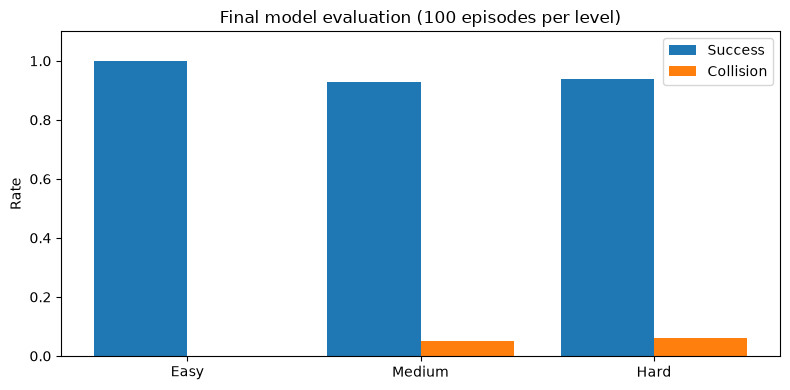

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(summary))
ax.bar([i - 0.2 for i in x], summary["success_rate"], width=0.4, label="Success")
ax.bar([i + 0.2 for i in x], summary["collision_rate"], width=0.4, label="Collision")
ax.set_xticks(list(x), summary["level"].str.title())
ax.set_ylim(0, 1.1)
ax.set_ylabel("Rate")
ax.set_title("Final model evaluation (100 episodes per level)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Training progress

Each point is the deterministic evaluation result saved at a training checkpoint. The star marks the selected model for that level.

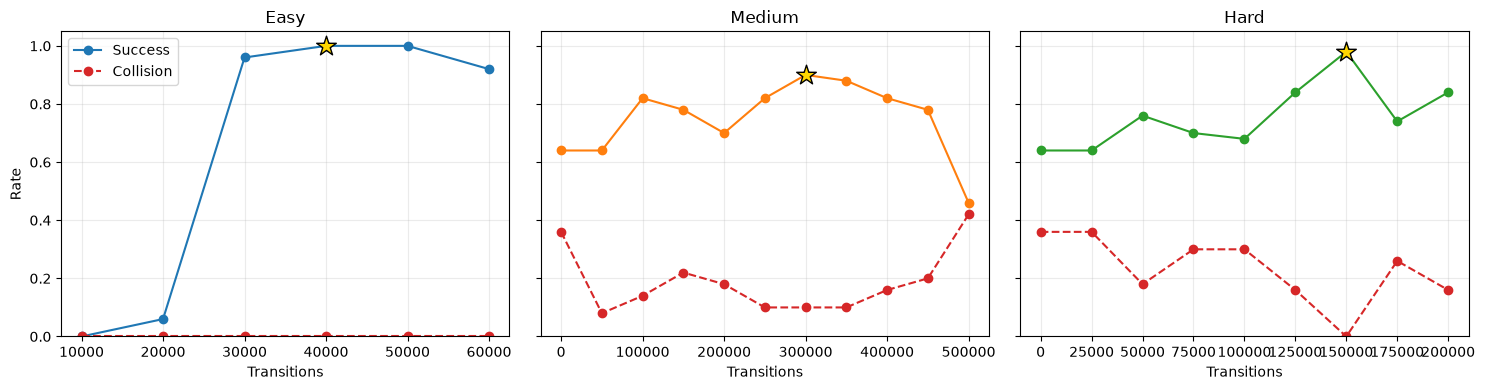

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
colors = {"easy": "#1f77b4", "medium": "#ff7f0e", "hard": "#2ca02c"}

for ax, level in zip(axes, ["easy", "medium", "hard"]):
    data = progress[progress["level"] == level]
    ax.plot(data["transitions"], data["success_rate"], "o-", label="Success", color=colors[level])
    ax.plot(data["transitions"], data["collision_rate"], "o--", label="Collision", color="#d62728")
    selected = data[data["selected"]]
    ax.scatter(selected["transitions"], selected["success_rate"], marker="*", s=220, color="gold", edgecolor="black", zorder=5)
    ax.set_title(level.title())
    ax.set_xlabel("Transitions")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Rate")
axes[0].legend()
plt.tight_layout()
plt.show()

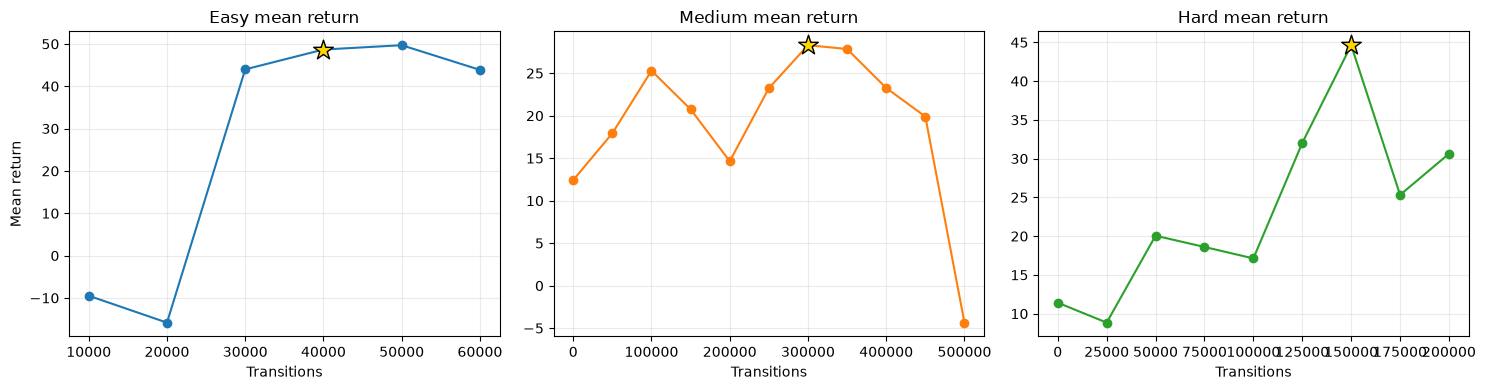

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, level in zip(axes, ["easy", "medium", "hard"]):
    data = progress[progress["level"] == level]
    ax.plot(data["transitions"], data["mean_return"], "o-", color=colors[level])
    selected = data[data["selected"]]
    ax.scatter(selected["transitions"], selected["mean_return"], marker="*", s=220, color="gold", edgecolor="black", zorder=5)
    ax.set_title(f"{level.title()} mean return")
    ax.set_xlabel("Transitions")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Mean return")
plt.tight_layout()
plt.show()

## 3. Selected models

- Easy: checkpoint 40k — 100% success on 100 evaluation episodes.
- Medium: checkpoint 300k — 93% success and 5% collision on 100 evaluation episodes.
- Hard: checkpoint 150k — 94% success and 6% collision on 100 evaluation episodes.

The final checkpoint was selected from the evaluation results rather than simply choosing the last checkpoint.

## 4. Hard-level policy video

In [6]:
Video(str(RESULTS_DIR / "hard_150k_demo.mp4"), embed=True)

## 5. Notes

- The three levels were trained with one seed per stage.
- Medium and Hard performance changed between checkpoints, so more training did not always improve the policy.
- The Hard model passed the target of at least 80% success and at most 10% collision.
- The models were evaluated in simulation and were not tested on a real drone.